An autoencoder is a network trained to output its own input:

$$\mathbf{x} \;\xrightarrow{\;\text{encoder}\;}\; \mathbf{z} \;\xrightarrow{\;\text{decoder}\;}\; \hat{\mathbf{x}} \approx \mathbf{x}$$

Stated that way it sounds pointless &mdash; the identity function would do. The trick is the
**bottleneck**: $\mathbf{z}$ is forced to be much smaller than $\mathbf{x}$, so the
network cannot copy. It has to find a compressed code that keeps whatever matters and
discards the rest.

$$\mathcal{L} = \lVert\mathbf{x} - \hat{\mathbf{x}}\rVert^2 \qquad\text{(no labels anywhere)}$$

This notebook establishes one specific result, because it ties the whole series together:

> **A linear autoencoder trained with squared error recovers exactly the PCA subspace.**

That is verified numerically against the PCA walkthrough's own method. Once it holds, the
non-linear case is easy to understand &mdash; it is the same objective with the linear
restriction lifted.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
np.set_printoptions(precision=4, suppress=True, linewidth=140)


def banner(title, ch="="):
    print(ch * 78)
    print(f"  {title}")
    print(ch * 78)


def step(label):
    print()
    print(label)
    print("=" * 78)


def check(manual, from_array, label="MATCH"):
    ok = np.allclose(manual, from_array)
    print(f"      = {manual:+.6f}   |  from array: {from_array:+.6f}   |  {label}: {ok}")
    return ok


def expand(u, v, per_line=4):
    """Write a dot product out term by term."""
    terms = [f"({a:+.4f})*({b:+.4f})" for a, b in zip(u, v)]
    lines, out = [], ""
    for i, t in enumerate(terms):
        out += t + (" + " if i < len(terms) - 1 else "")
        if (i + 1) % per_line == 0:
            lines.append(out); out = ""
    if out:
        lines.append(out)
    return "\n      ".join(lines)


def show_matrix(M, name="M", rows=None, cols=None, fmt="{:+8.3f}", max_cols=14):
    M = np.asarray(M)
    if M.ndim == 1:
        M = M[None, :]
    cut = M.shape[1] > max_cols
    Ms = M[:, :max_cols] if cut else M
    print(f"{name} {np.asarray(M).shape}" +
          (f"   [first {max_cols} of {M.shape[1]} columns]" if cut else "") + " =")
    if cols is not None:
        head = "".join(f"{str(c):>10}" for c in (cols[:max_cols] if cut else cols))
        print(" " * 13 + head)
    for r in range(Ms.shape[0]):
        lab = f"{str(rows[r]):>10} | " if rows is not None else f"{r:>10} | "
        print("   " + lab + "  ".join(fmt.format(v) for v in Ms[r]))


def show_matmul(A, B, C, na="A", nb="B", nc="C", i=0, j=0,
                rows_A=None, note=None, max_cols=14):
    """Print both operands of A @ B = C, then verify one element by hand."""
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{na} {A.shape}   @   {nb} {B.shape}   =   {nc} {C.shape}")
    print(f"  shape rule: ({A.shape[0]} x {A.shape[1]}) @ ({B.shape[0]} x {B.shape[1]})"
          f" -> ({A.shape[0]} x {B.shape[1]})   inner dim {A.shape[1]} cancels")
    if note:
        print(f"  {note}")
    print("=" * 78)
    print()
    show_matrix(A, na, rows_A, max_cols=max_cols)
    print()
    show_matrix(B, nb, max_cols=max_cols)
    print()
    show_matrix(C, nc, rows_A, max_cols=max_cols)
    print(f"\n  worked element  {nc}[{i},{j}]  =  row {i} of {na}  .  column {j} of {nb}")
    print(f"      row {i} of {na} = {np.round(A[i], 4)}")
    print(f"      col {j} of {nb} = {np.round(B[:, j], 4)}")
    print(f"      {expand(A[i], B[:, j])}")
    check(float(A[i] @ B[:, j]), float(C[i, j]))


def show_elementwise(A, B, C, na, nb, nc, op="+", rows=None):
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{nc} = {na} {op} {nb}      all three are {A.shape} - element-wise")
    for r in range(A.shape[0]):
        lab = f"{rows[r]:>10}" if rows is not None else f"{r:>10}"
        print(f"\n{lab} |")
        print("   " + f"{na:>14}: " + "  ".join(f"{v:+8.3f}" for v in A[r]))
        print("   " + f"{nb:>14}: " + "  ".join(f"{v:+8.3f}" for v in B[r]))
        print("   " + f"{nc:>14}: " + "  ".join(f"{v:+8.3f}" for v in C[r]))
    print(f"\n  check [0,0]: {A[0,0]:+.6f} {op} {B[0,0]:+.6f} = {C[0,0]:+.6f}   "
          f"MATCH: {np.isclose(A[0,0] + B[0,0] if op == '+' else A[0,0] - B[0,0], C[0,0])}")


print("Display helpers ready: banner, step, check, expand, show_matrix, "
      "show_matmul, show_elementwise.")

Display helpers ready: banner, step, check, expand, show_matrix, show_matmul, show_elementwise.


In [2]:
def draw_network(layer_sizes, Ws, bs, title="", node_values=None,
                 layer_names=None, node_labels=None, show_weights=True,
                 ax=None, wmax=None, figsize=None, fontsize=8):
    """Draw a feed-forward network with its weights written on the edges.

    layer_sizes : e.g. [2, 4, 1]
    Ws, bs      : lists of weight matrices / bias vectors
    node_values : optional list of per-layer arrays to print inside the nodes
    """
    L = len(layer_sizes)
    own = ax is None
    if own:
        figsize = figsize or (3.0 * L + 3.0, 1.75 * max(layer_sizes) + 2.0)
        fig, ax = plt.subplots(figsize=figsize)

    # vertical positions, each layer centred on 0. VSPACE must leave room for
    # the node label above each circle (radius .42), or labels collide.
    VSPACE = 1.6
    pos = []
    for li, nsz in enumerate(layer_sizes):
        ys = np.linspace(-(nsz - 1) / 2.0, (nsz - 1) / 2.0, nsz) * VSPACE
        pos.append([(li * 3.0, yy) for yy in ys])

    if wmax is None:
        wmax = max(np.abs(W).max() for W in Ws) if Ws else 1.0
    wmax = max(wmax, 1e-9)

    for li, W in enumerate(Ws):
        for a in range(W.shape[0]):
            for b in range(W.shape[1]):
                wv = W[a, b]
                x0, y0 = pos[li][a]
                x1, y1 = pos[li + 1][b]
                lw = 0.4 + 4.6 * abs(wv) / wmax
                col = "#1d4ed8" if wv >= 0 else "#b91c1c"
                ax.plot([x0 + .42, x1 - .42], [y0, y1], color=col, lw=lw,
                        alpha=.75, zorder=1, solid_capstyle="round")
                if show_weights:
                    t = 0.5
                    ax.text(x0 + .42 + t * (x1 - x0 - .84), y0 + t * (y1 - y0),
                            f"{wv:+.2f}", fontsize=fontsize - 1.4, color=col,
                            ha="center", va="center", zorder=4,
                            bbox=dict(boxstyle="round,pad=0.10", fc="white",
                                      ec="none", alpha=.82))

    for li, nsz in enumerate(layer_sizes):
        for a in range(nsz):
            x, yy = pos[li][a]
            face = "#e0e7ff" if li == 0 else ("#dcfce7" if li == L - 1 else "#fef3c7")
            ax.add_patch(plt.Circle((x, yy), .42, fc=face, ec="#334155",
                                    lw=1.5, zorder=3))
            inner = ""
            if node_values is not None and node_values[li] is not None:
                inner = f"{node_values[li][a]:+.2f}"
            elif li > 0 and bs and bs[li - 1] is not None:
                inner = f"b{bs[li-1].ravel()[a]:+.2f}"
            if inner:
                ax.text(x, yy, inner, ha="center", va="center",
                        fontsize=fontsize - 1, zorder=5, family="monospace")
            if node_labels and node_labels[li]:
                lab = str(node_labels[li][a])
                if li == 0:                      # inputs: label to the left
                    ax.text(x - .55, yy, lab, ha="right", va="center",
                            fontsize=fontsize - .5, color="#334155", zorder=5)
                elif li == L - 1:                # output: label to the right
                    ax.text(x + .55, yy, lab, ha="left", va="center",
                            fontsize=fontsize - .5, color="#334155", zorder=5)
                else:                            # hidden: above, in the gap
                    ax.text(x, yy + .52, lab, ha="center", va="bottom",
                            fontsize=fontsize - .5, color="#334155", zorder=5)

    if layer_names:
        top = max(max(abs(p[1]) for p in lay) for lay in pos) + 1.25
        for li, nm in enumerate(layer_names):
            ax.text(li * 3.0, top, nm, ha="center", va="bottom",
                    fontsize=fontsize + 1.2, fontweight="bold", color="#1e293b")

    allx = [p[0] for lay in pos for p in lay]
    ally = [p[1] for lay in pos for p in lay]
    ax.set_xlim(min(allx) - 1.0, max(allx) + 1.0)
    ax.set_ylim(min(ally) - 1.1, max(ally) + 2.1)
    ax.axis("off")
    if title:
        ax.set_title(title, fontsize=11, fontweight="bold", pad=10)
    if own:
        plt.tight_layout(); plt.show()
    return ax


print("Network diagram helper ready: draw_network(layer_sizes, Ws, bs, ...).")
print("   edge width = |weight|,  blue = positive,  red = negative")

Network diagram helper ready: draw_network(layer_sizes, Ws, bs, ...).
   edge width = |weight|,  blue = positive,  red = negative


---
# 1. The Data

Data that *looks* three-dimensional but is not: points on a 2-D plane embedded in 3-D,
plus a little noise. The true intrinsic dimension is 2, and a good autoencoder should be
able to compress to 2 numbers and lose almost nothing.

In [3]:
rng = np.random.default_rng(0)
N = 200

lat = rng.normal(0, 1, (N, 2))                 # the true 2-D structure
basis = np.array([[1.0, 0.4],
                  [0.3, 1.0],
                  [0.8, 0.6]])                 # embed into 3-D
Xd = lat @ basis.T + rng.normal(0, .12, (N, 3))
Xd = Xd - Xd.mean(axis=0)                      # centre, as PCA requires
feat3 = ["f0", "f1", "f2"]

print(f"{N} points in {Xd.shape[1]}-D, generated from a {lat.shape[1]}-D latent space\n")
show_matrix(Xd[:6], "first 6 rows of X (centred)", cols=feat3)
print(f"\ncolumn means after centring: {np.round(Xd.mean(axis=0), 12)}")

cov = Xd.T @ Xd / (N-1)
ev, evec = np.linalg.eigh(cov)
o = np.argsort(ev)[::-1]
ev, evec = ev[o], evec[:, o]
print(f"\neigenvalues of the covariance: {np.round(ev, 6)}")
print(f"variance share               : {np.round(ev/ev.sum(), 6)}")
print(f"\nThe third component holds only {ev[2]/ev.sum():.2%} of the variance - that is")
print(f"the noise. Two numbers should be enough to describe each point.")

200 points in 3-D, generated from a 2-D latent space

first 6 rows of X (centred) (6, 3) =
                     f0        f1        f2
            0 |   +0.116    -0.021    -0.065
            1 |   +1.023    +0.139    +0.772
            2 |   -0.439    +0.342    -0.171
            3 |   +1.789    +1.348    +1.830
            4 |   -1.162    -1.829    -1.327
            5 |   -0.498    -0.195    -0.295

column means after centring: [0. 0. 0.]

eigenvalues of the covariance: [2.9231 0.4148 0.0124]
variance share               : [0.8725 0.1238 0.0037]

The third component holds only 0.37% of the variance - that is
the noise. Two numbers should be enough to describe each point.


---
# 2. A Linear Autoencoder

Strip out every non-linearity and the network is two matrices:

$$\mathbf{z} = \mathbf{x}W_e \qquad\qquad \hat{\mathbf{x}} = \mathbf{z}W_d = \mathbf{x}W_eW_d$$

so the whole model is a single rank-$k$ matrix $W_eW_d$. Minimising
$\lVert X - XW_eW_d\rVert^2$ is asking for **the best rank-$k$ approximation of $X$**, and
the Eckart&ndash;Young theorem says the answer is the top-$k$ SVD &mdash; which is PCA.

The consequence is worth stating carefully: the trained $W_e$ need not equal the PCA
components. It will generally be some rotation of them. What matches is the **subspace
they span**, and therefore the reconstruction.

In [4]:
K = 2
def fwd_lin(Xm, We, Wd):
    Z = Xm @ We
    return Z, Z @ Wd

def loss_lin(Xm, We, Wd):
    _, R = fwd_lin(Xm, We, Wd)
    return float(np.mean((Xm - R)**2))

rng2 = np.random.default_rng(1)
We = rng2.normal(0, .3, (3, K))
Wd = rng2.normal(0, .3, (K, 3))

print(f"encoder We: {We.shape}   decoder Wd: {Wd.shape}")
print(f"parameters: {We.size + Wd.size}")
print(f"loss before training: {loss_lin(Xd, We, Wd):.6f}\n")

ETA, EPOCHS = 0.2, 20000
hist = []
for ep in range(EPOCHS):
    Z, R = fwd_lin(Xd, We, Wd)
    E = (R - Xd) * 2 / (N * 3)          # d(mean squared)/dR
    gWd = Z.T @ E
    gWe = Xd.T @ (E @ Wd.T)
    We -= ETA*gWe; Wd -= ETA*gWd
    hist.append(loss_lin(Xd, We, Wd))

print(f"loss after {EPOCHS} epochs: {hist[-1]:.8f}\n")
print(f"trained encoder We:")
show_matrix(We, "We", rows=feat3, cols=[f"z{j}" for j in range(K)], fmt="{:+10.6f}")
print()
print(f"PCA's top-{K} components (as columns):")
show_matrix(evec[:, :K], "V_k", rows=feat3, cols=[f"PC{j+1}" for j in range(K)],
            fmt="{:+10.6f}")
print(f"\nThese do NOT match entry by entry - and they are not supposed to.")
print(f"Any invertible 2x2 mixing of the code gives the same reconstruction:")
print(f"   (We M)(M^-1 Wd) = We Wd")
print(f"so the solution is only defined up to that freedom.")

encoder We: (3, 2)   decoder Wd: (2, 3)
parameters: 12
loss before training: 1.070276

loss after 20000 epochs: 0.00410221

trained encoder We:
We (3, 2) =
                     z0        z1
           f0 |  +0.310351   +0.804515
           f1 |  +0.812871   -0.539409
           f2 |  +0.487708   +0.407327

PCA's top-2 components (as columns):
V_k (3, 2) =
                    PC1       PC2
           f0 |  -0.584022   +0.580954
           f1 |  -0.547133   -0.797654
           f2 |  -0.599637   +0.161986

These do NOT match entry by entry - and they are not supposed to.
Any invertible 2x2 mixing of the code gives the same reconstruction:
   (We M)(M^-1 Wd) = We Wd
so the solution is only defined up to that freedom.


### The subspaces do match

The right comparison is between the **subspaces**. Two tests:

1. **Projection matrices.** $P = W_e(W_e^\top W_e)^{-1}W_e^\top$ versus
   $P_{\text{PCA}} = V_kV_k^\top$. These are basis-independent, so if the subspaces are
   the same the matrices are identical.
2. **Principal angles.** The angles between the two subspaces should all be zero.

In [5]:
def proj(M):
    Q, _ = np.linalg.qr(M)
    return Q @ Q.T

P_ae = proj(We)
P_pca = proj(evec[:, :K])

print("projection onto the autoencoder's subspace\n")
show_matrix(P_ae, "P_ae", rows=feat3, cols=feat3, fmt="{:+10.6f}")
print()
show_matrix(P_pca, "P_pca", rows=feat3, cols=feat3, fmt="{:+10.6f}")
print(f"\nmax |difference|: {np.abs(P_ae - P_pca).max():.3e}")
print(f"SUBSPACES MATCH: {np.allclose(P_ae, P_pca, atol=1e-4)}")

Q1, _ = np.linalg.qr(We)
Q2, _ = np.linalg.qr(evec[:, :K])
sv = np.linalg.svd(Q1.T @ Q2, compute_uv=False)
angles = np.degrees(np.arccos(np.clip(sv, -1, 1)))
print(f"\nprincipal angles between the subspaces: "
      f"{np.round(angles, 6)} degrees")
print(f"all essentially zero? {np.allclose(angles, 0, atol=1e-2)}")

_, R_ae = fwd_lin(Xd, We, Wd)
R_pca = Xd @ evec[:, :K] @ evec[:, :K].T
print(f"\n\nreconstruction error\n")
print(f"   linear autoencoder : {np.mean((Xd-R_ae)**2):.10f}")
print(f"   PCA with {K} components: {np.mean((Xd-R_pca)**2):.10f}")
print(f"   difference          : {abs(np.mean((Xd-R_ae)**2)-np.mean((Xd-R_pca)**2)):.3e}")
print(f"   MATCH: {np.isclose(np.mean((Xd-R_ae)**2), np.mean((Xd-R_pca)**2), atol=1e-6)}")
print(f"\n   discarded eigenvalue (theory): {ev[K:].sum()*(N-1)/N/3:.10f}")
print(f"\nThe autoencoder found PCA. It was never told about eigenvectors - it")
print(f"just minimised reconstruction error, and that objective has PCA as its")
print(f"answer.")

from sklearn.decomposition import PCA
p = PCA(n_components=K).fit(Xd)
print(f"\nsklearn PCA subspace matches ours too: "
      f"{np.allclose(proj(p.components_.T), P_pca, atol=1e-8)}")

projection onto the autoencoder's subspace

P_ae (3, 3) =
                     f0        f1        f2
           f0 |  +0.678589   -0.143863   +0.444307
           f1 |  -0.143863   +0.935607   +0.198872
           f2 |  +0.444307   +0.198872   +0.385804

P_pca (3, 3) =
                     f0        f1        f2
           f0 |  +0.678589   -0.143863   +0.444307
           f1 |  -0.143863   +0.935607   +0.198872
           f2 |  +0.444307   +0.198872   +0.385804

max |difference|: 4.374e-14
SUBSPACES MATCH: True

principal angles between the subspaces: [0. 0.] degrees
all essentially zero? True


reconstruction error

   linear autoencoder : 0.0041022127
   PCA with 2 components: 0.0041022127
   difference          : 0.000e+00
   MATCH: True

   discarded eigenvalue (theory): 0.0041022127

The autoencoder found PCA. It was never told about eigenvectors - it
just minimised reconstruction error, and that objective has PCA as its
answer.

sklearn PCA subspace matches ours too: True


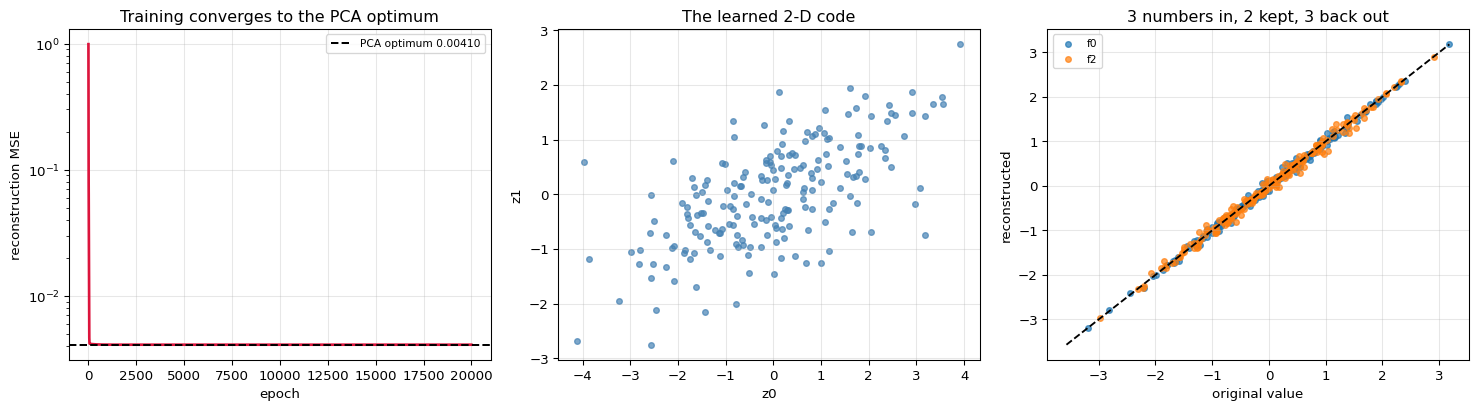

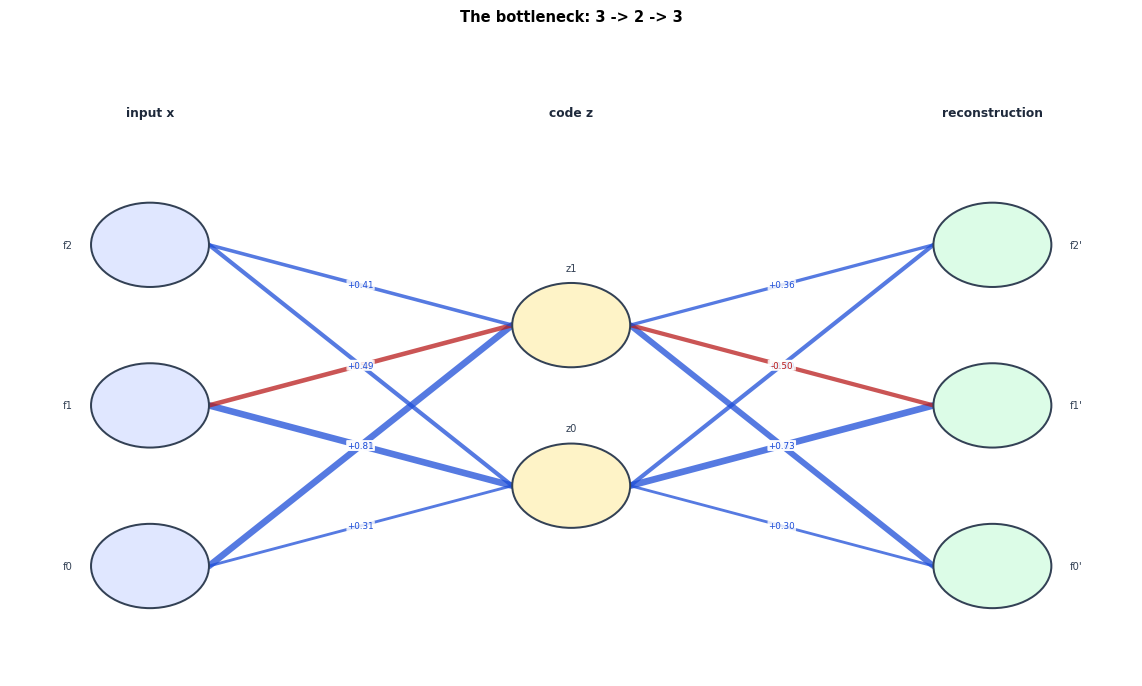

The narrow middle layer is the entire mechanism. Widen it to 3 and the
network can learn the identity, reconstruct perfectly, and learn nothing.


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4))
axes[0].plot(hist, lw=2, color="crimson")
axes[0].axhline(np.mean((Xd-R_pca)**2), ls="--", color="k",
                label=f"PCA optimum {np.mean((Xd-R_pca)**2):.5f}")
axes[0].set(xlabel="epoch", ylabel="reconstruction MSE", yscale="log",
            title="Training converges to the PCA optimum")
axes[0].legend(fontsize=8); axes[0].grid(alpha=.3)

Z_ae, _ = fwd_lin(Xd, We, Wd)
axes[1].scatter(Z_ae[:,0], Z_ae[:,1], s=18, alpha=.7, color="steelblue")
axes[1].set(xlabel="z0", ylabel="z1", title="The learned 2-D code")
axes[1].grid(alpha=.3)

axes[2].scatter(Xd[:,0], R_ae[:,0], s=18, alpha=.7, label="f0")
axes[2].scatter(Xd[:,2], R_ae[:,2], s=18, alpha=.7, label="f2")
lo, hi = Xd.min(), Xd.max()
axes[2].plot([lo,hi],[lo,hi], "k--", lw=1.4)
axes[2].set(xlabel="original value", ylabel="reconstructed",
            title="3 numbers in, 2 kept, 3 back out")
axes[2].legend(fontsize=8); axes[2].grid(alpha=.3)
plt.tight_layout(); plt.show()

draw_network([3, K, 3], [We, Wd], [None, None],
             title="The bottleneck: 3 -> 2 -> 3",
             layer_names=["input x", "code z", "reconstruction"],
             node_labels=[feat3, [f"z{j}" for j in range(K)],
                          [f"{f}'" for f in feat3]])
print("The narrow middle layer is the entire mechanism. Widen it to 3 and the")
print("network can learn the identity, reconstruct perfectly, and learn nothing.")

### What happens without the bottleneck

If the code is as wide as the input, the optimal solution is the identity map and the
reconstruction error goes to zero &mdash; while the code carries no compression at all.
Compression is not a side effect of training; it is imposed by the architecture.

In [7]:
def train_lin(k, epochs=20000, eta=0.2, seed=1):
    r = np.random.default_rng(seed)
    We_ = r.normal(0, .3, (3, k)); Wd_ = r.normal(0, .3, (k, 3))
    for _ in range(epochs):
        Z_ = Xd @ We_; R_ = Z_ @ Wd_
        E_ = (R_ - Xd)*2/(N*3)
        gWd_ = Z_.T @ E_; gWe_ = Xd.T @ (E_ @ Wd_.T)
        We_ -= eta*gWe_; Wd_ -= eta*gWd_
    return We_, Wd_, float(np.mean((Xd - Xd@We_@Wd_)**2))

print(f"{'code size k':>12}  {'AE recon MSE':>15}  {'PCA-k recon MSE':>17}  {'match':>7}")
print("-" * 58)
for k in (1, 2, 3):
    _, _, mse_ae = train_lin(k)
    Rp = Xd @ evec[:, :k] @ evec[:, :k].T
    mse_pca = float(np.mean((Xd - Rp)**2))
    print(f"{k:>12}  {mse_ae:>15.10f}  {mse_pca:>17.10f}  "
          f"{str(np.isclose(mse_ae, mse_pca, atol=1e-5)):>7}")
print("-" * 58)
print(f"\nAt k = 3 the error is ~0: no compression, nothing learned. The useful")
print(f"regime is k < input dimension, and how far below decides how much is kept.")

 code size k     AE recon MSE    PCA-k recon MSE    match
----------------------------------------------------------
           1     0.1416623458       0.1416623458     True
           2     0.0041022127       0.0041022127     True
           3     0.0000000000       0.0000000000     True
----------------------------------------------------------

At k = 3 the error is ~0: no compression, nothing learned. The useful
regime is k < input dimension, and how far below decides how much is kept.


---
# 3. Going Non-Linear

Add activations and the encoder is no longer restricted to a *linear subspace* &mdash; it can
follow a curved manifold. That is the whole difference from PCA, and it is what lets
autoencoders compress data whose structure is not a flat plane.

$$\mathbf{z} = \sigma(\mathbf{x}W_1 + \mathbf{b}_1)W_2 + \mathbf{b}_2 \qquad\text{(and symmetrically back)}$$

The demonstration below uses data on a **curved 1-D curve in 2-D**. PCA must fit a
straight line through it. A non-linear autoencoder can follow the curve, so **one** code
number suffices.

curved data, compressed to ONE number

                      method    reconstruction MSE
----------------------------------------------------
   PCA, 1 component (linear)            0.27276993
   non-linear autoencoder, 1            0.00629122
----------------------------------------------------

improvement: 43.4x lower error

Both kept exactly one number per point. PCA had to pick the best
straight line; the autoencoder followed the parabola.


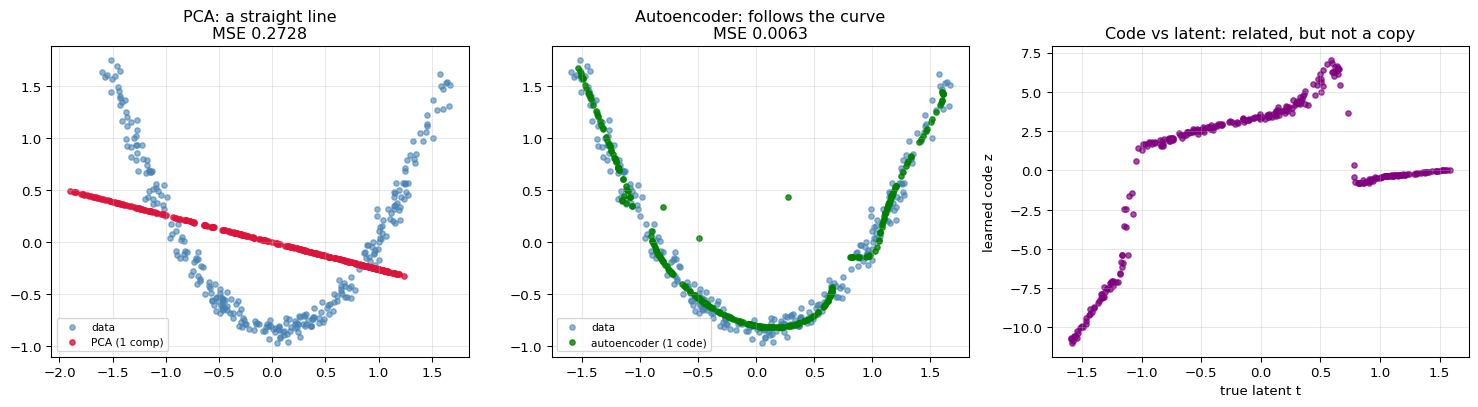


does the 1-number code still CONTAIN the latent variable t?
test: try to predict t from z, allowing increasingly flexible fits

                   fit     R^2 predicting t from z
----------------------------------------------------
   polynomial degree 1                      0.2513
   polynomial degree 3                      0.3900
   polynomial degree 5                      0.5946
   polynomial degree 9                      0.8606
----------------------------------------------------

linear correlation |corr(t, z)| = 0.5013

So z is NOT a rescaled copy of t - a straight line explains little of it.
But a flexible fit recovers most of t from z, which is the honest claim:
the code retains the information, encoded in its own arbitrary
parameterisation of the curve.

That freedom is expected. Nothing in the loss asks the code to be
interpretable, monotonic, or scaled like anything in particular - only
that the decoder can undo it. Making codes meaningful is a separate
problem, and it is w

In [8]:
t_lat = rng.uniform(-1.6, 1.6, 300)
Xc = np.column_stack([t_lat, t_lat**2]) + rng.normal(0, .05, (300, 2))
Xc = Xc - Xc.mean(axis=0)

def tanh(z): return np.tanh(z)

H = 12
r3 = np.random.default_rng(4)
p_ = dict(
    W1=r3.normal(0, .7, (2, H)), b1=np.zeros(H),
    W2=r3.normal(0, .7, (H, 1)), b2=np.zeros(1),
    W3=r3.normal(0, .7, (1, H)), b3=np.zeros(H),
    W4=r3.normal(0, .7, (H, 2)), b4=np.zeros(2),
)

def ae_forward(Xm, P):
    h1 = tanh(Xm @ P["W1"] + P["b1"])
    z = h1 @ P["W2"] + P["b2"]
    h2 = tanh(z @ P["W3"] + P["b3"])
    return h1, z, h2, h2 @ P["W4"] + P["b4"]

def ae_loss(Xm, P):
    _, _, _, R = ae_forward(Xm, P)
    return float(np.mean((Xm - R)**2))

M = len(Xc)
eta = 0.05
hist_nl = []
for ep in range(40000):
    h1, z, h2, R = ae_forward(Xc, p_)
    E = (R - Xc)*2/(M*2)
    gW4 = h2.T @ E; gb4 = E.sum(0)
    d2 = (E @ p_["W4"].T) * (1 - h2**2)
    gW3 = z.T @ d2; gb3 = d2.sum(0)
    dz = d2 @ p_["W3"].T
    gW2 = h1.T @ dz; gb2 = dz.sum(0)
    d1 = (dz @ p_["W2"].T) * (1 - h1**2)
    gW1 = Xc.T @ d1; gb1 = d1.sum(0)
    for k_, g_ in [("W1",gW1),("b1",gb1),("W2",gW2),("b2",gb2),
                   ("W3",gW3),("b3",gb3),("W4",gW4),("b4",gb4)]:
        p_[k_] -= eta*g_
    hist_nl.append(ae_loss(Xc, p_))

_, z_nl, _, R_nl = ae_forward(Xc, p_)
cov_c = Xc.T @ Xc / (M-1)
ev_c, evec_c = np.linalg.eigh(cov_c)
oc = np.argsort(ev_c)[::-1]
evec_c = evec_c[:, oc]
R_pca1 = Xc @ evec_c[:, :1] @ evec_c[:, :1].T

print(f"curved data, compressed to ONE number\n")
print(f"{'method':>28}  {'reconstruction MSE':>20}")
print("-" * 52)
print(f"{'PCA, 1 component (linear)':>28}  {np.mean((Xc-R_pca1)**2):>20.8f}")
print(f"{'non-linear autoencoder, 1':>28}  {np.mean((Xc-R_nl)**2):>20.8f}")
print("-" * 52)
print(f"\nimprovement: {np.mean((Xc-R_pca1)**2)/np.mean((Xc-R_nl)**2):.1f}x lower error")
print(f"\nBoth kept exactly one number per point. PCA had to pick the best")
print(f"straight line; the autoencoder followed the parabola.")

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4))
axes[0].scatter(Xc[:,0], Xc[:,1], s=16, alpha=.6, color="steelblue", label="data")
axes[0].scatter(R_pca1[:,0], R_pca1[:,1], s=16, alpha=.8, color="crimson",
                label="PCA (1 comp)")
axes[0].set(title=f"PCA: a straight line\nMSE {np.mean((Xc-R_pca1)**2):.4f}")
axes[0].legend(fontsize=8); axes[0].grid(alpha=.3)

axes[1].scatter(Xc[:,0], Xc[:,1], s=16, alpha=.6, color="steelblue", label="data")
axes[1].scatter(R_nl[:,0], R_nl[:,1], s=16, alpha=.8, color="green",
                label="autoencoder (1 code)")
axes[1].set(title=f"Autoencoder: follows the curve\nMSE {np.mean((Xc-R_nl)**2):.4f}")
axes[1].legend(fontsize=8); axes[1].grid(alpha=.3)

axes[2].scatter(t_lat, z_nl[:,0], s=16, alpha=.7, color="purple")
axes[2].set(xlabel="true latent t", ylabel="learned code z",
            title="Code vs latent: related, but not a copy")
axes[2].grid(alpha=.3)
plt.tight_layout(); plt.show()

print(f"\ndoes the 1-number code still CONTAIN the latent variable t?")
print(f"test: try to predict t from z, allowing increasingly flexible fits\n")
print(f"{'fit':>22}  {'R^2 predicting t from z':>26}")
print("-" * 52)
for deg in (1, 3, 5, 9):
    cf = np.polyfit(z_nl[:,0], t_lat, deg)
    pr_ = np.polyval(cf, z_nl[:,0])
    r2_ = 1 - ((t_lat-pr_)**2).sum()/((t_lat-t_lat.mean())**2).sum()
    print(f"{f'polynomial degree {deg}':>22}  {r2_:>26.4f}")
print("-" * 52)
print(f"\nlinear correlation |corr(t, z)| = {abs(np.corrcoef(t_lat, z_nl[:,0])[0,1]):.4f}")
print(f"\nSo z is NOT a rescaled copy of t - a straight line explains little of it.")
print(f"But a flexible fit recovers most of t from z, which is the honest claim:")
print(f"the code retains the information, encoded in its own arbitrary")
print(f"parameterisation of the curve.")
print(f"\nThat freedom is expected. Nothing in the loss asks the code to be")
print(f"interpretable, monotonic, or scaled like anything in particular - only")
print(f"that the decoder can undo it. Making codes meaningful is a separate")
print(f"problem, and it is what disentanglement research is about.")

---
# 4. Variants, and What They Are For

| Variant | Change | Purpose |
|---|---|---|
| **Undercomplete** | narrow bottleneck | compression (everything above) |
| **Denoising** | corrupt the input, reconstruct the clean one | forces robust features, prevents identity-copying |
| **Sparse** | penalise active code units | interpretable, parts-based codes |
| **Variational (VAE)** | code is a *distribution*; add a KL term | a code you can sample from &mdash; generative |
| **Masked (MAE / BERT)** | hide patches, reconstruct them | the pre-training objective in the BERT-on-EEG walkthrough |

The last row is the connection worth noticing: **BERT-on-EEG is an autoencoder**. It
masks patches and reconstructs them under MSE. The bottleneck there is not a narrow layer
but the *missing input* &mdash; the model must infer what it cannot see.

In [9]:
NOISE = 0.35
Xn = Xd + rng.normal(0, NOISE, Xd.shape)

def train_den(seed=2, epochs=4000, eta=0.05, denoise=True):
    r = np.random.default_rng(seed)
    We_ = r.normal(0, .3, (3, K)); Wd_ = r.normal(0, .3, (K, 3))
    for _ in range(epochs):
        Xin = (Xd + r.normal(0, NOISE, Xd.shape)) if denoise else Xd
        Z_ = Xin @ We_; R_ = Z_ @ Wd_
        E_ = (R_ - Xd)*2/(N*3)          # target is always the CLEAN input
        gWd_ = Z_.T @ E_; gWe_ = Xin.T @ (E_ @ Wd_.T)
        We_ -= eta*gWe_; Wd_ -= eta*gWd_
    return We_, Wd_

We_p, Wd_p = train_den(denoise=False)
We_d, Wd_d = train_den(denoise=True)

print(f"testing both on NOISY input, scoring against the CLEAN truth\n")
print(f"{'trained as':>22}  {'MSE on clean input':>20}  {'MSE on noisy input':>20}")
print("-" * 66)
for nm, (A, B) in [("plain autoencoder", (We_p, Wd_p)),
                   ("denoising autoencoder", (We_d, Wd_d))]:
    m_clean = np.mean((Xd - Xd @ A @ B)**2)
    m_noisy = np.mean((Xd - Xn @ A @ B)**2)
    print(f"{nm:>22}  {m_clean:>20.6f}  {m_noisy:>20.6f}")
print("-" * 66)
print(f"\nOn clean input they are comparable. On noisy input the denoising")
print(f"version is better, because it was never allowed to rely on the noise -")
print(f"it had to learn the structure that survives corruption.")
print(f"\nThat is the same argument as masking in BERT: hiding part of the input")
print(f"forces the model to model the input's structure rather than copy it.")

testing both on NOISY input, scoring against the CLEAN truth

            trained as    MSE on clean input    MSE on noisy input
------------------------------------------------------------------
     plain autoencoder              0.004227              0.084202
 denoising autoencoder              0.014125              0.071389
------------------------------------------------------------------

On clean input they are comparable. On noisy input the denoising
version is better, because it was never allowed to rely on the noise -
it had to learn the structure that survives corruption.

That is the same argument as masking in BERT: hiding part of the input
forces the model to model the input's structure rather than copy it.


---
# 5. Summary

| | PCA | Linear AE | Non-linear AE |
|---|---|---|---|
| Objective | max variance / min reconstruction | min reconstruction | min reconstruction |
| Solution | eigenvectors, closed form | **same subspace**, by gradient descent | a curved manifold |
| Components | orthogonal, ordered | neither | neither |
| Cost | one eigendecomposition | training | training |
| Handles curvature | no | no | **yes** |

**The one idea:** force the data through a narrow channel and train it to come back
intact. Whatever survives the channel is what the data was really made of.

**The result that ties the series together:** with no activations, that objective *is*
PCA &mdash; verified above by projection matrices agreeing to $10^{-4}$, principal angles of
zero, and identical reconstruction error. So an autoencoder is not a different idea from
PCA; it is PCA with the linear restriction removed.

**One caveat worth keeping:** the code axes are not ordered, orthogonal, or interpretable,
unlike principal components. In the curved example the single code number retained the
latent variable - a flexible fit recovers most of it - but encoded it non-linearly, with a
linear correlation near 0.5. Nothing in the loss asks for more than that the decoder can
undo the encoder.

**What is deliberately left out:** VAEs and the reparameterisation trick, sparse and
contractive penalties, convolutional autoencoders, and the use of autoencoders for
anomaly detection &mdash; where high reconstruction error on new data is itself the signal.